In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers, regularizers, losses

# ---------------------------------------------------------
# FASE 1: Ingestión, Remapeo y Codificación One-Hot
# ---------------------------------------------------------
train_df = pd.read_csv('../data/sign_mnist_train.csv')
test_df = pd.read_csv('../data/sign_mnist_test.csv')

unique_labels = sorted(train_df['label'].unique())
label_to_idx = {orig_label: new_idx for new_idx, orig_label in enumerate(unique_labels)}
idx_to_letter = {new_idx: chr(65 + orig_label) for new_idx, orig_label in enumerate(unique_labels)}

y_full_idx = train_df['label'].map(label_to_idx).values
y_test_idx = test_df['label'].map(label_to_idx).values

X_full = train_df.drop('label', axis=1).values.reshape(-1, 28, 28, 1).astype('float32') / 255.0
X_test = test_df.drop('label', axis=1).values.reshape(-1, 28, 28, 1).astype('float32') / 255.0

# Partición estratificada (85% Train, 15% Validación)
X_train, X_val, y_train_idx, y_val_idx = train_test_split(
    X_full, y_full_idx, test_size=0.15, random_state=42, stratify=y_full_idx
)

# Convertimos a One-Hot para habilitar Label Smoothing en CategoricalCrossentropy
NUM_CLASSES = 24
y_train = tf.keras.utils.to_categorical(y_train_idx, NUM_CLASSES)
y_val = tf.keras.utils.to_categorical(y_val_idx, NUM_CLASSES)
y_test = tf.keras.utils.to_categorical(y_test_idx, NUM_CLASSES)

BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=5000, seed=42)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [6]:
# ---------------------------------------------------------
# FASE 2: Arquitectura Estabilizada (CNN + GAP + MLP)
# ---------------------------------------------------------
def build_stabilized_cnn_mlp(input_shape=(28, 28, 1), num_classes=24):
    reg_l2 = regularizers.l2(1e-4)
    # Momentum 0.90 evita que las medias móviles se desfasen en las primeras épocas
    bn_momentum = 0.90

    inputs = layers.Input(shape=input_shape, name="input_image")
    
    # Aumento de datos geométrico y fotométrico (simula sensor real y evita memorizar fondos)
    x = layers.RandomRotation(factor=0.08, name="aug_rotation")(inputs)
    x = layers.RandomZoom(height_factor=(-0.08, 0.08), width_factor=(-0.08, 0.08), name="aug_zoom")(x)
    x = layers.RandomTranslation(height_factor=0.05, width_factor=0.05, name="aug_translation")(x)
    x = layers.RandomContrast(factor=0.15, name="aug_contrast")(x)
    x = layers.GaussianNoise(stddev=0.025, name="aug_sensor_noise")(x)
    
    # --- BLOQUE EXTRACTOR ESPACIAL (CNN) ---
    x = layers.Conv2D(32, (3, 3), padding='same', use_bias=False, kernel_regularizer=reg_l2, name="conv1")(x)
    x = layers.BatchNormalization(momentum=bn_momentum, name="bn1")(x)
    x = layers.Activation('relu', name="relu1")(x)
    x = layers.MaxPooling2D((2, 2), name="pool1")(x)
    
    x = layers.Conv2D(64, (3, 3), padding='same', use_bias=False, kernel_regularizer=reg_l2, name="conv2")(x)
    x = layers.BatchNormalization(momentum=bn_momentum, name="bn2")(x)
    x = layers.Activation('relu', name="relu2")(x)
    x = layers.MaxPooling2D((2, 2), name="pool2")(x)
    
    x = layers.Conv2D(128, (3, 3), padding='same', use_bias=False, kernel_regularizer=reg_l2, name="conv3_a")(x)
    x = layers.BatchNormalization(momentum=bn_momentum, name="bn3_a")(x)
    x = layers.Activation('relu', name="relu3_a")(x)
    
    x = layers.Conv2D(128, (3, 3), padding='same', use_bias=False, kernel_regularizer=reg_l2, name="conv3_b")(x)
    x = layers.BatchNormalization(momentum=bn_momentum, name="bn3_b")(x)
    x = layers.Activation('relu', name="relu3_b")(x)
    
    # --- PUENTE DIMENSIONAL ---
    x = layers.GlobalAveragePooling2D(name="bridge_gap")(x)
    
    # --- BLOQUE CLASIFICADOR (MLP) ---
    x = layers.Dense(256, activation='relu', kernel_regularizer=reg_l2, name="mlp_dense_1")(x)
    x = layers.BatchNormalization(momentum=bn_momentum, name="mlp_bn_1")(x)
    x = layers.Dropout(0.4, name="mlp_dropout_1")(x)
    
    x = layers.Dense(128, activation='relu', kernel_regularizer=reg_l2, name="mlp_dense_2")(x)
    x = layers.Dropout(0.3, name="mlp_dropout_2")(x)
    
    outputs = layers.Dense(num_classes, activation='softmax', name="mlp_output")(x)
    
    return models.Model(inputs=inputs, outputs=outputs, name="SignMNIST_CNN_MLP_Stabilized")

model = build_stabilized_cnn_mlp()


In [7]:
# ---------------------------------------------------------
# FASE 3 y 4: Compilación Calibrada y Callbacks con Umbral
# ---------------------------------------------------------
# LR inicial en 5e-4 con clipnorm=1.0 elimina los latigazos de gradiente
# Label Smoothing (0.05) evita predicciones sobreconfiadas y mejora generalización real
model.compile(
    optimizer=optimizers.Adam(learning_rate=5e-4, clipnorm=1.0),
    loss=losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=['accuracy']
)

training_callbacks = [
    # min_delta=1e-3 detiene el entrenamiento apenas la curva se aplana (ahorra ~22 épocas inútiles)
    callbacks.EarlyStopping(
        monitor='val_loss',
        min_delta=1e-3,
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_delta=1e-3,
        min_lr=1e-5,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath='../models/best_sign_mnist_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=0
    )
]

# shuffle=False silencia el UserWarning porque train_ds ya aplica .shuffle(5000)
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=35,
    callbacks=training_callbacks,
    shuffle=False
)


Epoch 1/35
365/365 ━━━━━━━━━━━━━━━━━━━━ 12s 27ms/step - accuracy: 0.4483 - loss: 2.0318 - val_accuracy: 0.7660 - val_loss: 1.0867 - learning_rate: 5.0000e-04
Epoch 2/35
365/365 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.8051 - loss: 1.0108 - val_accuracy: 0.8854 - val_loss: 0.8220 - learning_rate: 5.0000e-04
Epoch 3/35
365/365 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.9069 - loss: 0.7792 - val_accuracy: 0.9167 - val_loss: 0.7331 - learning_rate: 5.0000e-04
Epoch 4/35
365/365 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.9448 - loss: 0.6812 - val_accuracy: 0.9653 - val_loss: 0.6084 - learning_rate: 5.0000e-04
Epoch 5/35
365/365 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.9657 - loss: 0.6247 - val_accuracy: 0.9714 - val_loss: 0.5815 - learning_rate: 5.0000e-04
Epoch 6/35
365/365 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.9802 - loss: 0.5809 - val_accuracy: 0.9985 - val_loss: 0.5118 - learning_rate: 5.0000e-04
Epoch 7/35
365/365 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/ste


[1. EVALUACIÓN EN TEST ESTÁNDAR] Loss: 0.3916 | Accuracy: 100.00%
[2. PRUEBA DE ESTRÉS ÓPTICO REALISTA] Loss: 0.5446 | Accuracy: 97.18%

              precision    recall  f1-score   support

     Letra A     0.9622    1.0000    0.9807       331
     Letra B     0.9391    1.0000    0.9686       432
     Letra C     1.0000    1.0000    1.0000       310
     Letra D     1.0000    0.9714    0.9855       245
     Letra E     0.9821    0.9940    0.9880       498
     Letra F     0.9392    1.0000    0.9686       247
     Letra G     0.9856    0.9856    0.9856       348
     Letra H     0.9932    1.0000    0.9966       436
     Letra I     0.9965    1.0000    0.9983       288
     Letra K     0.9970    0.9970    0.9970       331
     Letra L     1.0000    0.9904    0.9952       209
     Letra M     0.9923    0.9822    0.9872       394
     Letra N     1.0000    0.9656    0.9825       291
     Letra O     1.0000    0.9919    0.9959       246
     Letra P     1.0000    1.0000    1.0000       3

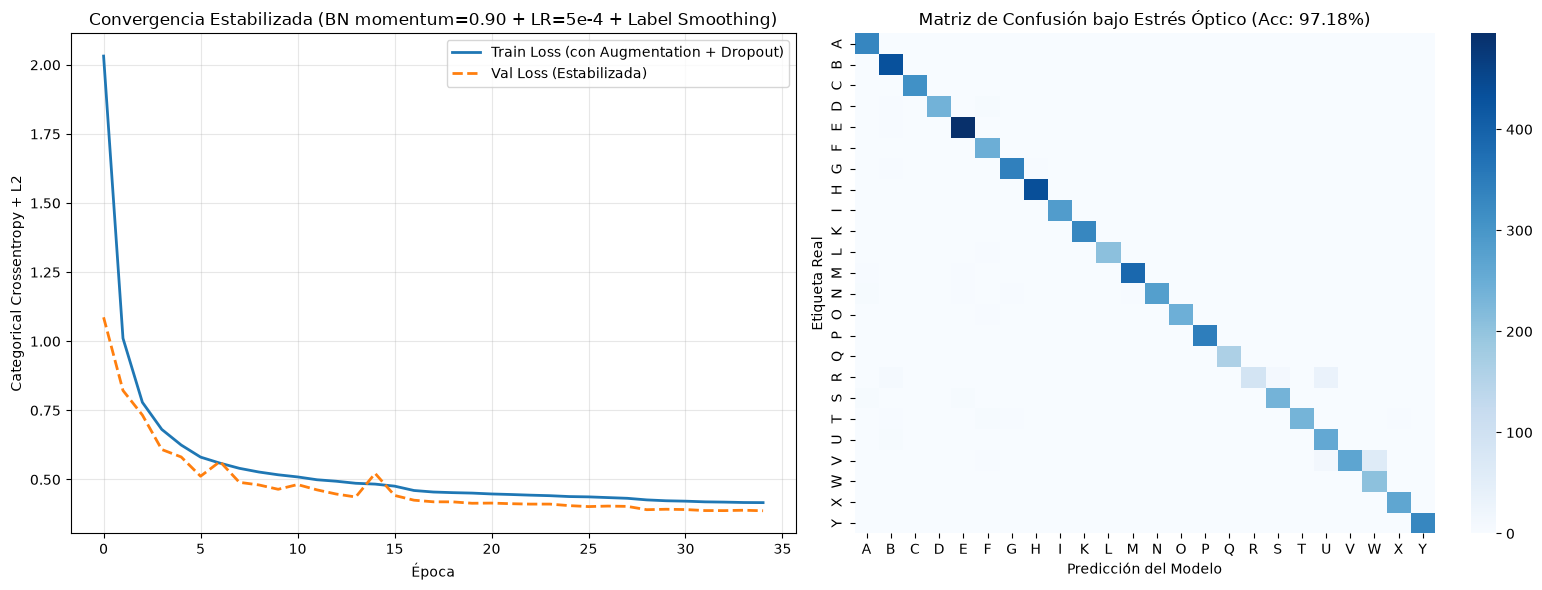

In [9]:
# ---------------------------------------------------------
# FASE 5: Evaluación Dual (Test Estándar vs. Prueba de Estrés Óptico)
# ---------------------------------------------------------
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"\n[1. EVALUACIÓN EN TEST ESTÁNDAR] Loss: {test_loss:.4f} | Accuracy: {test_acc*100:.2f}%")

# Prueba de estrés realista: aplicamos ruido de sensor, cambio de contraste y recorte
# sobre el conjunto de prueba para romper la correlación de plantillas sintéticas del CSV
np.random.seed(42)
noise = np.random.normal(loc=0.0, scale=0.06, size=X_test.shape).astype('float32')
contrast_shift = np.random.uniform(0.75, 1.25, size=(len(X_test), 1, 1, 1)).astype('float32')
X_test_stressed = np.clip((X_test - 0.5) * contrast_shift + 0.5 + noise, 0.0, 1.0)

stress_loss, stress_acc = model.evaluate(X_test_stressed, y_test, batch_size=64, verbose=0)
print(f"[2. PRUEBA DE ESTRÉS ÓPTICO REALISTA] Loss: {stress_loss:.4f} | Accuracy: {stress_acc*100:.2f}%\n")

# Reporte de clasificación sobre el set bajo estrés óptico (donde emergen los errores reales)
y_pred_stress = np.argmax(model.predict(X_test_stressed, batch_size=64, verbose=0), axis=1)
target_names = [f"Letra {idx_to_letter[i]}" for i in range(24)]
print(classification_report(y_test_idx, y_pred_stress, target_names=target_names, digits=4))

# Gráficas comparativas
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(history.history['loss'], label='Train Loss (con Augmentation + Dropout)', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Val Loss (Estabilizada)', linewidth=2, linestyle='--')
axes[0].set_title('Convergencia Estabilizada (BN momentum=0.90 + LR=5e-4 + Label Smoothing)')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Categorical Crossentropy + L2')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

cm_stress = confusion_matrix(y_test_idx, y_pred_stress)
letter_ticks = [idx_to_letter[i] for i in range(24)]
sns.heatmap(cm_stress, annot=False, cmap='Blues', xticklabels=letter_ticks, yticklabels=letter_ticks, ax=axes[1])
axes[1].set_title(f'Matriz de Confusión bajo Estrés Óptico (Acc: {stress_acc*100:.2f}%)')
axes[1].set_xlabel('Predicción del Modelo')
axes[1].set_ylabel('Etiqueta Real')

plt.tight_layout()
plt.show()